# Notebook 1 — Datos

**Práctica 3 · Aprendizaje Automático**

Integrantes: Michael Franco, Michael Lata, Jordy Romero, Nayeli Barbecho

Este cuaderno cubre todo lo relacionado con **datos**: carga del dataset sintético de
la Práctica 2, validación, ingeniería de features (incluyendo las variables nuevas
pedidas en `Feedback Empresas.pdf` §IV.A), calidad de datos por producto y preparación
de los targets multi-horizonte que usará el notebook `02_procesos.ipynb`.

No se regenera el dataset sintético — se reutiliza tal cual el de la Práctica 2, tal
como se decidió para esta iteración (la mejora es sobre las *features*, no sobre el
generador).

## 1. Configuración y carga de datos crudos

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))

from practica3.features import (  # noqa: E402
    FEATURE_COLS, HORIZONTES, MIN_DIAS_HISTORICOS,
    agregar_targets, calidad_datos_por_producto,
    cargar_datos_crudos, construir_dataset_diario,
)

plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["figure.dpi"] = 110

DATA_RAW = ROOT / "data" / "raw"
DATA_PROCESSED = ROOT / "data" / "processed"
DATA_PROCESSED.mkdir(parents=True, exist_ok=True)

inventory, sales = cargar_datos_crudos(DATA_RAW)
print(f"inventory : {inventory.shape}")
print(f"sales     : {sales.shape}  | nulos: {sales.isnull().sum().sum()}")
print(f"periodo   : {sales['fecha_venta'].min().date()} -> {sales['fecha_venta'].max().date()}")
print(f"productos : {sorted(sales['product_id'].unique())}")
inventory

inventory : (10, 6)
sales     : (1800, 5)  | nulos: 0
periodo   : 2026-04-05 -> 2026-10-01
productos : [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]


,product_id,nombre,categoria,unidad,stock_actual,fecha_expiracion
0,1,Laptop Gamer,Electronica,Unidades,282,2027-10-01
1,2,Monitor 4K,Electronica,Unidades,272,2027-10-01
2,3,Teclado Mecanico,Accesorios,Unidades,194,2027-10-01
3,4,Raton Inal.,Accesorios,Unidades,286,2027-10-01
4,5,Cable USB-C,Cables,Unidades,251,2027-10-01
5,6,Adaptador HDMI,Cables,Unidades,200,2027-10-01
6,7,Webcam HD,Perifericos,Unidades,282,2027-10-01
7,8,Auriculares BT,Accesorios,Unidades,301,2027-10-01
8,9,Hub USB 3.0,Perifericos,Unidades,254,2027-10-01
9,10,Cargador Rapido,Cables,Unidades,267,2027-10-01


## 2. Validación de datos crudos

Antes de construir features se valida que no haya nulos y que los 10 productos
tengan el mismo rango de fechas — cualquier hueco aquí se propagaría como sesgo
silencioso al resto del pipeline.

In [2]:
dias_por_producto = sales.groupby("product_id")["fecha_venta"].nunique()
assert sales.isnull().sum().sum() == 0, "Hay nulos en el crudo"
assert dias_por_producto.nunique() == 1, "Productos con distinto número de días"
print("OK — sin nulos, todos los productos con", dias_por_producto.iloc[0], "días de historia")

OK — sin nulos, todos los productos con 180 días de historia


## 3. Construcción del dataset diario y features

`construir_dataset_diario` (en `src/practica3/features.py`) agrega por (fecha,
producto) y calcula las 25 columnas de `FEATURE_COLS`:

- **12 originales** (Práctica 2 / Informe SVM): calendario, stock, categoría, lags y
  medias móviles a 7 días.
- **13 nuevas**: más historia (`lag_2`, `lag_14`, rolling a 14 días), codificación
  cíclica de día/mes (mejor para un kernel RBF que un entero crudo), calendario
  extendido (`es_fecha_especial`, `temporada_seca`) y las variables exógenas
  sintéticas pedidas por las empresas (`promocion_activa`, `clima_lluvia`,
  `flujo_clientes_estimado`) — sintéticas porque todavía no llega el Excel real.

In [3]:
df = construir_dataset_diario(sales, inventory)
print(f"dataset diario: {df.shape}  | columnas nuevas: {len(FEATURE_COLS) - 12}")
df[["fecha", "product_id", "nombre", "cantidad_vendida"] + FEATURE_COLS].head(10)

dataset diario: (1800, 30)  | columnas nuevas: 13


,fecha,product_id,nombre,cantidad_vendida,cantidad_vendida,dia_semana,mes,es_weekend,es_feriado,dias_desde_inicio,...,rolling_std_14,dia_semana_sin,dia_semana_cos,mes_sin,mes_cos,es_fecha_especial,temporada_seca,promocion_activa,clima_lluvia,flujo_clientes_estimado
0,2026-04-05,1,Laptop Gamer,2,2,6,4,1,0,0,...,NaN,-0.781831,0.623490,0.866025,-0.5,0,0,0,0,68.6
1,2026-04-06,1,Laptop Gamer,6,6,0,4,0,0,1,...,NaN,0.000000,1.000000,0.866025,-0.5,0,0,0,0,39.5
2,2026-04-07,1,Laptop Gamer,7,7,1,4,0,0,2,...,NaN,0.781831,0.623490,0.866025,-0.5,0,0,0,1,40.1
3,2026-04-08,1,Laptop Gamer,10,10,2,4,0,0,3,...,NaN,0.974928,-0.222521,0.866025,-0.5,0,0,0,0,45.3
4,2026-04-09,1,Laptop Gamer,5,5,3,4,0,0,4,...,NaN,0.433884,-0.900969,0.866025,-0.5,0,0,0,0,34.2
5,2026-04-10,1,Laptop Gamer,6,6,4,4,0,0,5,...,NaN,-0.433884,-0.900969,0.866025,-0.5,0,0,0,0,40.3
6,2026-04-11,1,Laptop Gamer,5,5,5,4,1,0,6,...,NaN,-0.974928,-0.222521,0.866025,-0.5,0,0,0,1,62.5
7,2026-04-12,1,Laptop Gamer,3,3,6,4,1,0,7,...,NaN,-0.781831,0.623490,0.866025,-0.5,1,0,0,1,52.3
8,2026-04-13,1,Laptop Gamer,10,10,0,4,0,0,8,...,NaN,0.000000,1.000000,0.866025,-0.5,0,0,0,1,32.6
9,2026-04-14,1,Laptop Gamer,6,6,1,4,0,0,9,...,NaN,0.781831,0.623490,0.866025,-0.5,0,0,0,1,52.5


## 4. EDA — demanda y variables nuevas

In [4]:
print("Distribución de demanda (todos los productos):")
print(df["cantidad_vendida"].describe().round(2))

resumen = (
    df.groupby("nombre")["cantidad_vendida"]
    .agg(media="mean", std="std", min="min", max="max")
    .round(2)
    .sort_values("media", ascending=False)
)
print()
print(resumen.to_string())

Distribución de demanda (todos los productos):
count    1800.00
mean       15.39
std         7.56
min         0.00
25%        10.00
50%        14.00
75%        20.00
max        51.00
Name: cantidad_vendida, dtype: float64

                  media   std  min  max
nombre                                 
Cable USB-C       23.08  9.43    0   45
Cargador Rapido   21.59  8.50    0   51
Raton Inal.       19.38  7.57    0   44
Adaptador HDMI    18.37  5.33    2   36
Teclado Mecanico  15.68  4.67    5   35
Auriculares BT    14.37  4.17    0   28
Monitor 4K        11.76  3.99    3   24
Hub USB 3.0       11.42  3.92    3   28
Webcam HD         10.26  3.55    3   32
Laptop Gamer       8.01  3.17    1   20


### 4.1 Tendencia temporal (top-2 productos)

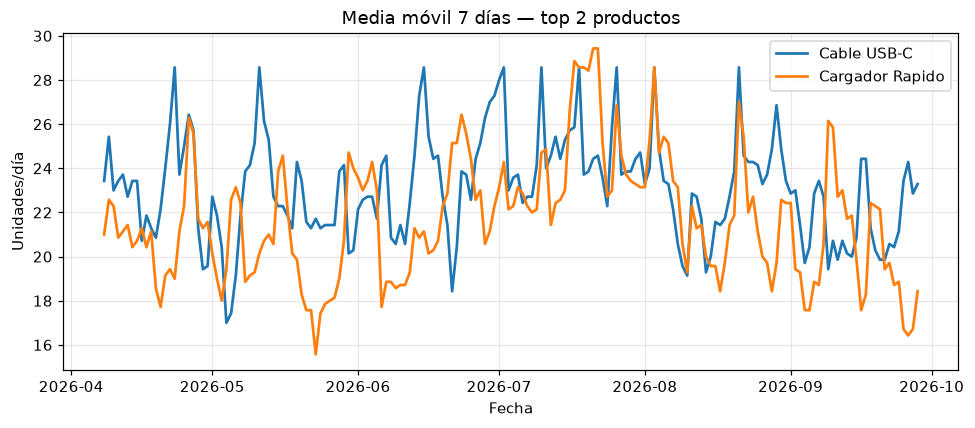

In [5]:
top2 = resumen.index[:2]
fig, ax = plt.subplots()
for nombre in top2:
    serie = df[df["nombre"] == nombre].set_index("fecha")["cantidad_vendida"]
    ax.plot(serie.index, serie.rolling(7, center=True).mean(), label=nombre, lw=1.8)
ax.set_title("Media móvil 7 días — top 2 productos")
ax.set_xlabel("Fecha"); ax.set_ylabel("Unidades/día"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### 4.2 ¿Las variables exógenas nuevas muestran patrón visible?

Comparación honesta: si `promocion_activa` o `clima_lluvia` no muestran diferencia
real en la demanda promedio, es porque son sintéticas e independientes del generador
de la Práctica 2 — no se fuerza ninguna correlación artificial. El notebook 2 medirá
su importancia real dentro del modelo (permutation importance).

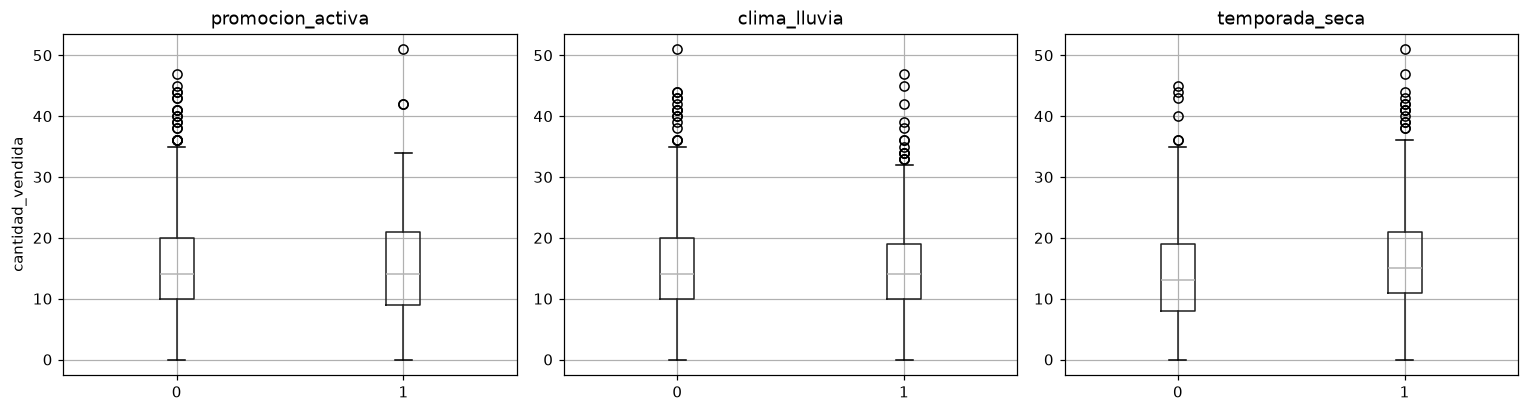

promocion_activa     -> media por grupo: {0: 15.38, 1: 15.54}
clima_lluvia         -> media por grupo: {0: 15.6, 1: 14.87}
temporada_seca       -> media por grupo: {0: 14.02, 1: 16.04}
es_fecha_especial    -> media por grupo: {0: 15.41, 1: 13.5}


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["promocion_activa", "clima_lluvia", "temporada_seca"]):
    df.boxplot(column="cantidad_vendida", by=col, ax=ax)
    ax.set_title(col); ax.set_xlabel(""); ax.set_ylabel("cantidad_vendida" if ax is axes[0] else "")
plt.suptitle("")
plt.tight_layout(); plt.show()

for col in ["promocion_activa", "clima_lluvia", "temporada_seca", "es_fecha_especial"]:
    medias = df.groupby(col)["cantidad_vendida"].mean().round(2)
    print(f"{col:20s} -> media por grupo: {medias.to_dict()}")

## 5. Calidad de datos por producto

Punto §IV.C del feedback empresarial: el sistema debe **advertir cuando la historia
disponible es insuficiente**, no solo predecir a ciegas. Se define un mínimo de
`MIN_DIAS_HISTORICOS` días; cualquier producto por debajo queda marcado y la API
bajará el nivel de confianza de sus predicciones (ver notebook 3 y
`src/practica3/inference.py`).

In [7]:
calidad = calidad_datos_por_producto(df, minimo=MIN_DIAS_HISTORICOS)
print(f"umbral mínimo de días históricos: {MIN_DIAS_HISTORICOS}")
display_cols = ["product_id", "nombre", "n_dias", "fecha_min", "fecha_max", "calidad_suficiente"]
print(calidad[display_cols].to_string(index=False))

calidad.assign(
    fecha_min=lambda d: d["fecha_min"].astype(str),
    fecha_max=lambda d: d["fecha_max"].astype(str),
)[display_cols].to_json(DATA_PROCESSED / "data_quality_report.json", orient="records", indent=2)
print("\nGuardado: data/processed/data_quality_report.json")

umbral mínimo de días históricos: 30
 product_id           nombre  n_dias  fecha_min  fecha_max  calidad_suficiente
          1     Laptop Gamer     180 2026-04-05 2026-10-01                True
          2       Monitor 4K     180 2026-04-05 2026-10-01                True
          3 Teclado Mecanico     180 2026-04-05 2026-10-01                True
          4      Raton Inal.     180 2026-04-05 2026-10-01                True
          5      Cable USB-C     180 2026-04-05 2026-10-01                True
          6   Adaptador HDMI     180 2026-04-05 2026-10-01                True
          7        Webcam HD     180 2026-04-05 2026-10-01                True
          8   Auriculares BT     180 2026-04-05 2026-10-01                True
          9      Hub USB 3.0     180 2026-04-05 2026-10-01                True
         10  Cargador Rapido     180 2026-04-05 2026-10-01                True

Guardado: data/processed/data_quality_report.json


## 6. Targets multi-horizonte

Punto §V.3 del feedback: predicciones a distintos horizontes, no solo t+1. Se agregan
`target_h1`, `target_h3` y `target_h7` (demanda del producto `h` días después de la
fila de referencia), reutilizando la misma fila de features — igual que el Informe
SVM, que ya usa `cantidad_vendida` del día como feature conocida para predecir el
día siguiente.

In [8]:
df = agregar_targets(df, HORIZONTES)
for h in HORIZONTES:
    n_validas = df[f"target_h{h}"].notna().sum()
    print(f"target_h{h}: {n_validas} filas con target válido")
df[["fecha", "product_id", "cantidad_vendida"] + [f"target_h{h}" for h in HORIZONTES]].tail(10)

target_h1: 1790 filas con target válido
target_h3: 1770 filas con target válido
target_h7: 1730 filas con target válido


,fecha,product_id,cantidad_vendida,target_h1,target_h3,target_h7
1790,2026-09-22,10,21,19.0,20.0,19.0
1791,2026-09-23,10,19,3.0,17.0,21.0
1792,2026-09-24,10,3,20.0,23.0,15.0
1793,2026-09-25,10,20,17.0,14.0,NaN
1794,2026-09-26,10,17,23.0,19.0,NaN
1795,2026-09-27,10,23,14.0,21.0,NaN
1796,2026-09-28,10,14,19.0,15.0,NaN
1797,2026-09-29,10,19,21.0,NaN,NaN
1798,2026-09-30,10,21,15.0,NaN,NaN
1799,2026-10-01,10,15,NaN,NaN,NaN


## 7. Guardado de artefactos para el notebook 2

In [9]:
df.to_parquet(DATA_PROCESSED / "dataset_features.parquet", index=False)

with open(DATA_PROCESSED / "features.json", "w") as f:
    json.dump({
        "feature_cols": FEATURE_COLS,
        "horizontes": list(HORIZONTES),
        "min_dias_historicos": MIN_DIAS_HISTORICOS,
        "n_filas": len(df),
        "n_productos": int(df["product_id"].nunique()),
    }, f, indent=2)

print("Guardado:")
print(f"  data/processed/dataset_features.parquet  ({df.shape[0]} filas x {df.shape[1]} columnas)")
print("  data/processed/features.json")

Guardado:
  data/processed/dataset_features.parquet  (1800 filas x 33 columnas)
  data/processed/features.json


## 8. Checklist de validación

In [10]:
checks = [
    ("Datos crudos cargados sin nulos", sales.isnull().sum().sum() == 0),
    ("Dataset diario construido", len(df) > 0),
    ("25 features calculadas", len(FEATURE_COLS) == 25),
    ("Variables exógenas nuevas presentes",
     {"promocion_activa", "clima_lluvia", "flujo_clientes_estimado"}.issubset(df.columns)),
    ("Codificación cíclica presente", {"dia_semana_sin", "mes_cos"}.issubset(df.columns)),
    ("Calidad de datos por producto calculada", len(calidad) == df["product_id"].nunique()),
    ("Targets multi-horizonte generados", all(f"target_h{h}" in df.columns for h in HORIZONTES)),
    ("Parquet procesado guardado", (DATA_PROCESSED / "dataset_features.parquet").exists()),
]
for nombre, ok in checks:
    print(("[OK] " if ok else "[FALTA] ") + nombre)
assert all(ok for _, ok in checks), "Hay checks pendientes"


[OK] Datos crudos cargados sin nulos
[OK] Dataset diario construido
[OK] 25 features calculadas
[OK] Variables exógenas nuevas presentes
[OK] Codificación cíclica presente
[OK] Calidad de datos por producto calculada
[OK] Targets multi-horizonte generados
[OK] Parquet procesado guardado


## Conclusiones

- Se reutilizó el dataset sintético de la Práctica 2 sin alterarlo, y se amplió de
  **12 a 25 features**: más historia temporal, codificación cíclica y variables
  exógenas sintéticas pedidas por las empresas en `Feedback Empresas.pdf`.
- Se añadió un chequeo explícito de **calidad de datos por producto**, para que el
  sistema pueda advertir cuando la historia disponible es insuficiente en vez de
  predecir a ciegas.
- Se prepararon **targets a 3 horizontes** (`t+1`, `t+3`, `t+7`) para que el notebook
  2 entrene un modelo por horizonte.
- Todo queda persistido en `data/processed/` para que `02_procesos.ipynb` no dependa
  de re-ejecutar este notebook.